In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset-ccn_project_trafficSignrecognation.zip to dataset-ccn_project_trafficSignrecognation.zip


In [ ]:
import zipfile
import os

zip_path = "/content/dataset-ccn_project_trafficSignrecognation.zip"
extract_path = "/content/traffic_sign_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Completed!")
print("Dataset folders:", os.listdir(extract_path))

Extraction Completed!
Dataset folders: ['Test.csv', 'Test', 'Train', 'Meta.csv', 'Train.csv', 'Meta', 'signnames.csv']


In [24]:
train_csv = pd.read_csv('/content/traffic_sign_dataset/Train.csv')
test_csv = pd.read_csv('/content/traffic_sign_dataset/Test.csv')
signnames = pd.read_csv('/content/traffic_sign_dataset/signnames.csv')

print("Train Shape:", train_csv.shape)
print("Test Shape:", test_csv.shape)

print("\nTrain Columns:")
print(train_csv.columns)

print("\nNumber of Classes:", train_csv['ClassId'].nunique())

print("\nSign Names:")
print(signnames.head())

Train Shape: (39209, 8)
Test Shape: (12630, 8)

Train Columns:
Index(['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId',
       'Path'],
      dtype='object')

Number of Classes: 43

Sign Names:
   ClassId              SignName
0        0  Speed limit (20km/h)
1        1  Speed limit (30km/h)
2        2  Speed limit (50km/h)
3        3  Speed limit (60km/h)
4        4  Speed limit (70km/h)


In [25]:
print("First 5 image paths:")
print(train_csv['Path'].head())

print("\nFirst image exists:",
      os.path.exists('/content/traffic_sign_dataset/' +
                     train_csv['Path'].iloc[0].replace('/code/', '')))

First 5 image paths:
0    /code/Train/20/00020_00000_00000.png
1    /code/Train/20/00020_00000_00001.png
2    /code/Train/20/00020_00000_00002.png
3    /code/Train/20/00020_00000_00003.png
4    /code/Train/20/00020_00000_00004.png
Name: Path, dtype: object

First image exists: True


In [27]:
from sklearn.model_selection import train_test_split
import os

# Correct image paths
train_paths = [
    os.path.join('/content/traffic_sign_dataset', p.replace('/code/', ''))
    for p in train_csv['Path']
]

test_paths = [
    os.path.join('/content/traffic_sign_dataset', p.replace('/code/', ''))
    for p in test_csv['Path']
]

# Labels
train_labels = train_csv['ClassId'].values
test_labels = test_csv['ClassId'].values

# Train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    train_paths,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(test_paths))

print("\nTraining path exists:", os.path.exists(X_train[0]))
print("Validation path exists:", os.path.exists(X_val[0]))
print("Testing path exists:", os.path.exists(test_paths[0]))

Training images: 31367
Validation images: 7842
Testing images: 12630

Training path exists: True
Validation path exists: True
Testing path exists: True


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)

    return image, label


def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_dataset(X_train, y_train, training=True)
val_dataset = create_dataset(X_val, y_val)
test_dataset = create_dataset(test_paths, test_labels)

print("All datasets are ready!")

All datasets are ready!


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Add custom classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(43, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

print("MobileNetV2 model loaded successfully!")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 model loaded successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,313,067 (8.82 MB)

 Trainable params: 55,083 (215.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [28]:
# Evaluate Without Fine-Tuning Model

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Without Fine-Tuning Test Accuracy:",
      test_accuracy * 100, "%")

print("Without Fine-Tuning Test Loss:", test_loss)

395/395 ━━━━━━━━━━━━━━━━━━━━ 170s 429ms/step - accuracy: 0.8868 - loss: 0.5720
Without Fine-Tuning Test Accuracy: 88.67775201797485 %
Without Fine-Tuning Test Loss: 0.5720403790473938


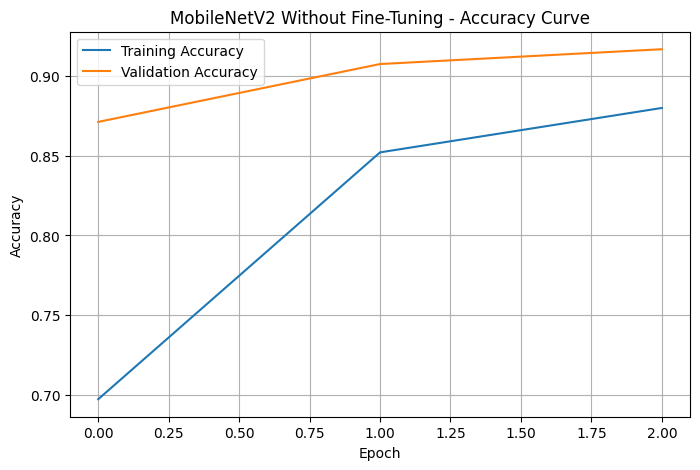

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_head.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_head.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('MobileNetV2 Without Fine-Tuning - Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

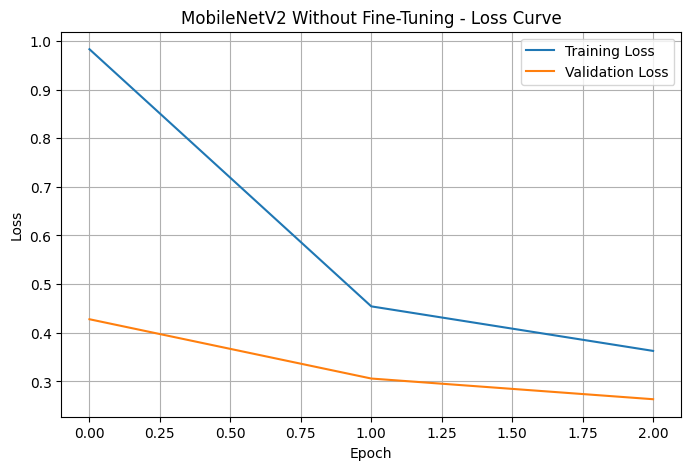

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_head.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_head.history['val_loss'],
    label='Validation Loss'
)

plt.title('MobileNetV2 Without Fine-Tuning - Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
from sklearn.metrics import classification_report

y_pred_prob = model.predict(test_dataset)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = test_labels

target_names = signnames.sort_values('ClassId')['SignName'].tolist()

print("Classification Report - Without Fine-Tuning")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(43)),
    target_names=target_names,
    digits=4,
    zero_division=0
))

395/395 ━━━━━━━━━━━━━━━━━━━━ 173s 436ms/step
Classification Report - Without Fine-Tuning
                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     0.9787    0.7667    0.8598        60
                              Speed limit (30km/h)     0.8868    0.9139    0.9001       720
                              Speed limit (50km/h)     0.7769    0.8960    0.8322       750
                              Speed limit (60km/h)     0.8337    0.7689    0.8000       450
                              Speed limit (70km/h)     0.9366    0.9182    0.9273       660
                              Speed limit (80km/h)     0.8859    0.8254    0.8546       630
                       End of speed limit (80km/h)     0.9683    0.8133    0.8841       150
                             Speed limit (100km/h)     0.9439    0.8978    0.9203       450
                             Speed limit (120km/h)     0.8562    0.8467    0.8514 

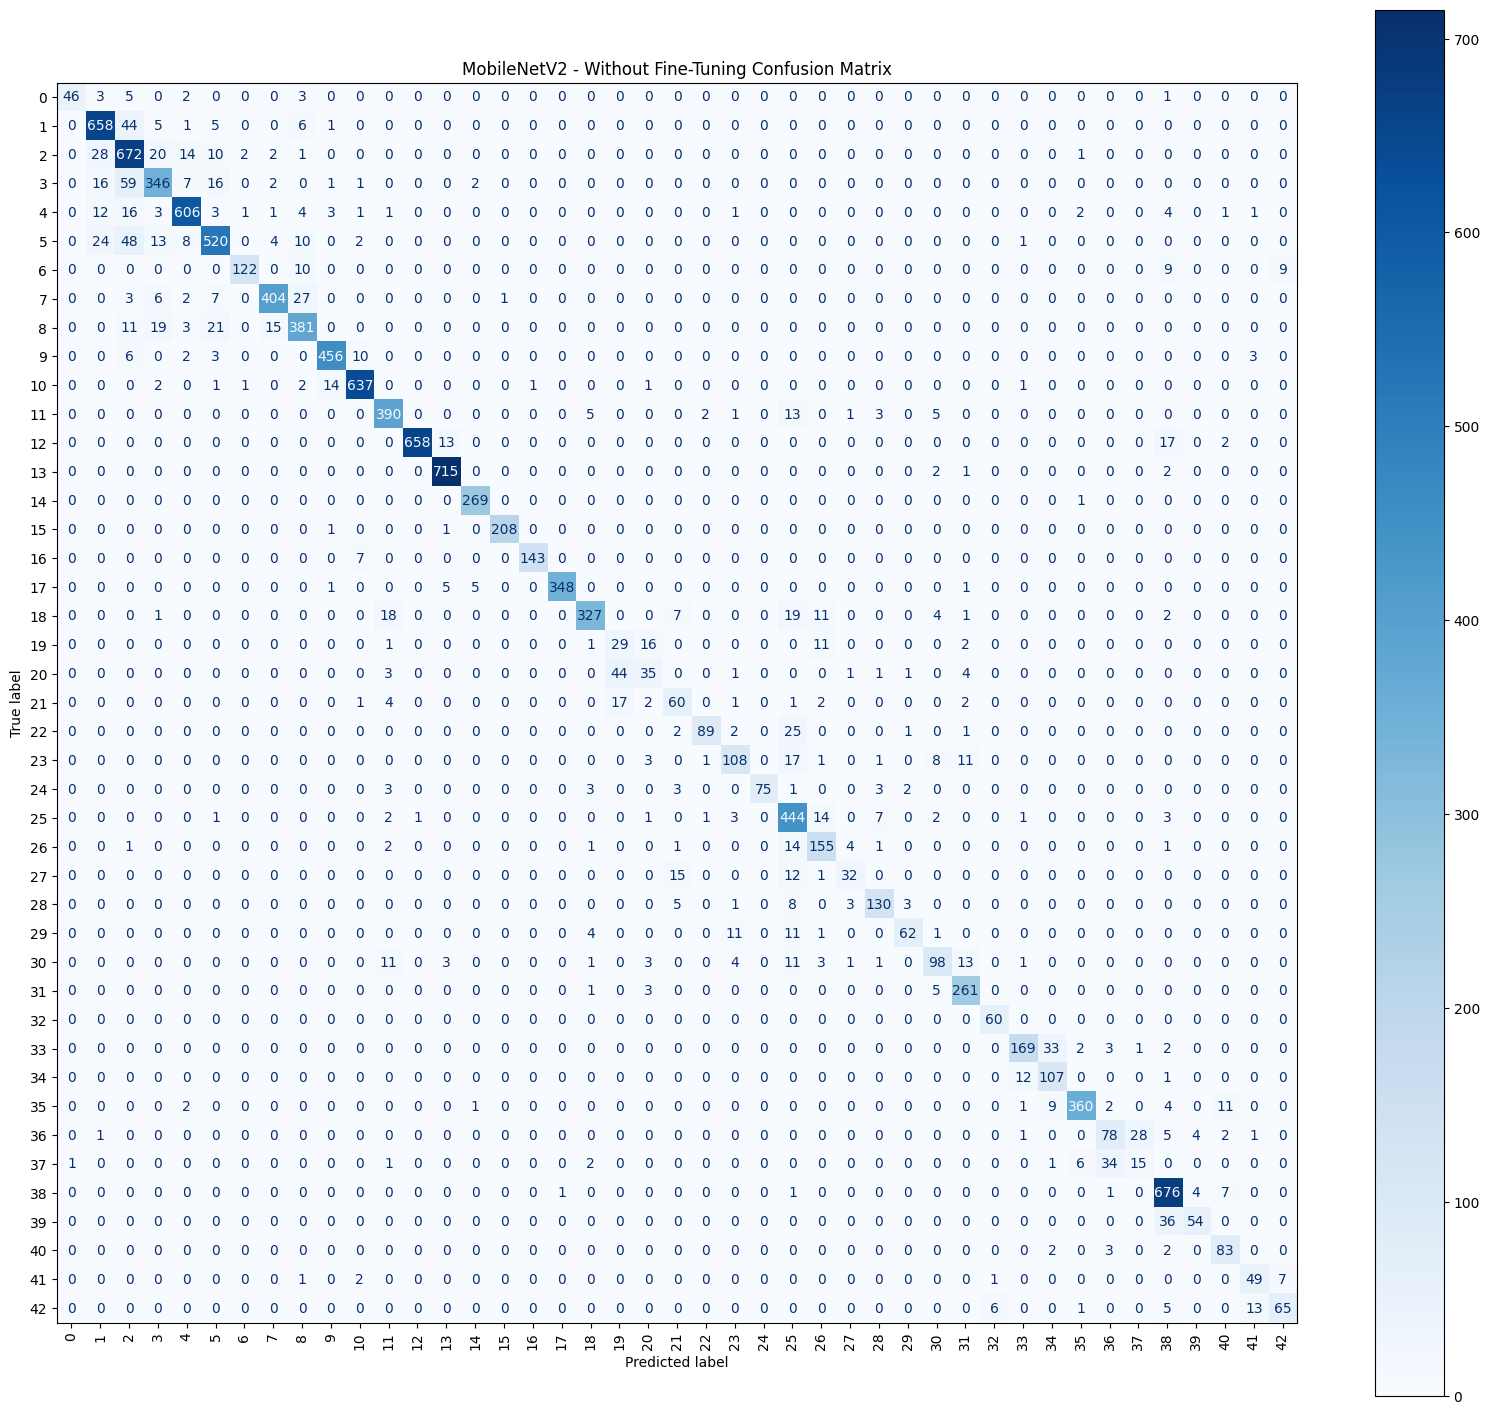

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(43))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(43))
)

disp.plot(
    cmap='Blues',
    xticks_rotation='vertical',
    values_format='d'
)

plt.gcf().set_size_inches(20, 18)

plt.title('MobileNetV2 - Without Fine-Tuning Confusion Matrix')

plt.show()

In [ ]:
history_head = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3
)

Epoch 1/3
981/981 ━━━━━━━━━━━━━━━━━━━━ 520s 524ms/step - accuracy: 0.6972 - loss: 0.9829 - val_accuracy: 0.8713 - val_loss: 0.4279
Epoch 2/3
981/981 ━━━━━━━━━━━━━━━━━━━━ 593s 556ms/step - accuracy: 0.8522 - loss: 0.4543 - val_accuracy: 0.9077 - val_loss: 0.3059
Epoch 3/3
981/981 ━━━━━━━━━━━━━━━━━━━━ 546s 556ms/step - accuracy: 0.8801 - loss: 0.3628 - val_accuracy: 0.9170 - val_loss: 0.2634


In [ ]:
# Unfreeze the pretrained MobileNetV2 model
base_model.trainable = True

# Freeze earlier layers, fine-tune only the last 40 layers
for layer in base_model.layers[:-40]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a low learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning preparation completed!")

Fine-tuning preparation completed!


In [ ]:
history_fine = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]
)

Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 699s 702ms/step - accuracy: 0.9171 - loss: 0.2485 - val_accuracy: 0.9452 - val_loss: 0.1693 - learning_rate: 1.0000e-05
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 785s 746ms/step - accuracy: 0.9459 - loss: 0.1657 - val_accuracy: 0.9540 - val_loss: 0.1417 - learning_rate: 1.0000e-05
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 728s 732ms/step - accuracy: 0.9594 - loss: 0.1234 - val_accuracy: 0.9668 - val_loss: 0.1062 - learning_rate: 1.0000e-05
Epoch 4/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 753s 744ms/step - accuracy: 0.9674 - loss: 0.0981 - val_accuracy: 0.9708 - val_loss: 0.0885 - learning_rate: 1.0000e-05
Epoch 5/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 743s 745ms/step - accuracy: 0.9760 - loss: 0.0745 - val_accuracy: 0.9740 - val_loss: 0.0824 - learning_rate: 1.0000e-05
Epoch 6/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 701s 703ms/step - accuracy: 0.9811 - loss: 0.0611 - val_accuracy: 0.9778 - val_loss: 0.0692 - learning_rate: 1.0000e-05
Epoch 7/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
# Combine both training histories

acc = history_head.history['accuracy'] + history_fine.history['accuracy']
val_acc = history_head.history['val_accuracy'] + history_fine.history['val_accuracy']

loss = history_head.history['loss'] + history_fine.history['loss']
val_loss = history_head.history['val_loss'] + history_fine.history['val_loss']

epochs_range = range(1, len(acc) + 1)

print("Total Epochs:", len(acc))

Total Epochs: 33


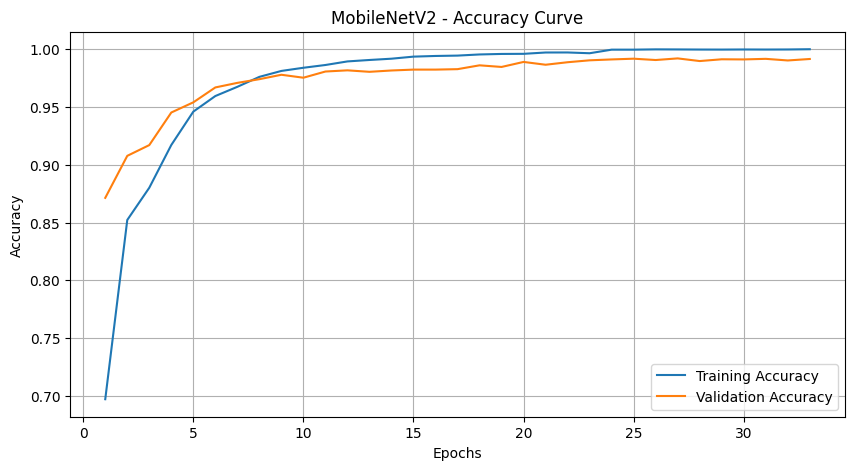

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.title('MobileNetV2 - Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

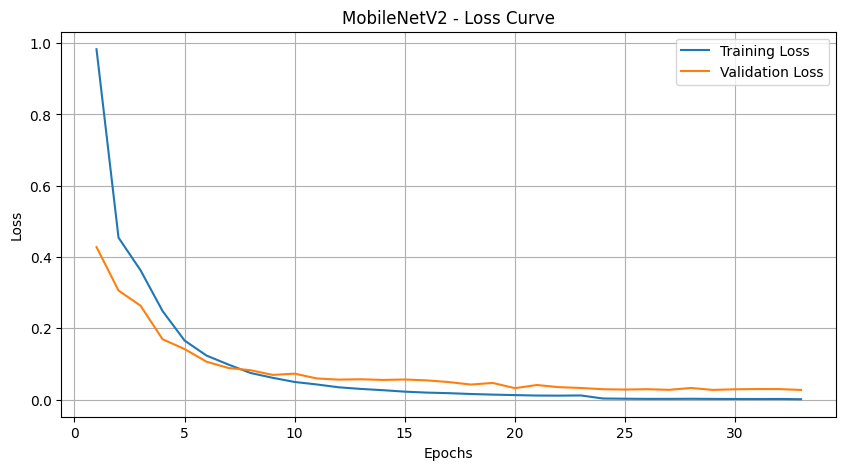

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.title('MobileNetV2 - Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predict test dataset
y_pred_prob = model.predict(test_dataset)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual labels
y_true = test_labels

print("Predictions completed!")
print("Total predictions:", len(y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 177s 432ms/step
Predictions completed!
Total predictions: 12630


In [ ]:
from sklearn.metrics import classification_report

target_names = signnames.sort_values('ClassId')['SignName'].tolist()

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(43)),
    target_names=target_names,
    digits=4,
    zero_division=0
))

                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     0.9787    0.7667    0.8598        60
                              Speed limit (30km/h)     0.8868    0.9139    0.9001       720
                              Speed limit (50km/h)     0.7769    0.8960    0.8322       750
                              Speed limit (60km/h)     0.8337    0.7689    0.8000       450
                              Speed limit (70km/h)     0.9366    0.9182    0.9273       660
                              Speed limit (80km/h)     0.8859    0.8254    0.8546       630
                       End of speed limit (80km/h)     0.9683    0.8133    0.8841       150
                             Speed limit (100km/h)     0.9439    0.8978    0.9203       450
                             Speed limit (120km/h)     0.8562    0.8467    0.8514       450
                                        No passing     0.9560    0.9500    0.95

<Figure size 2000x1800 with 0 Axes>

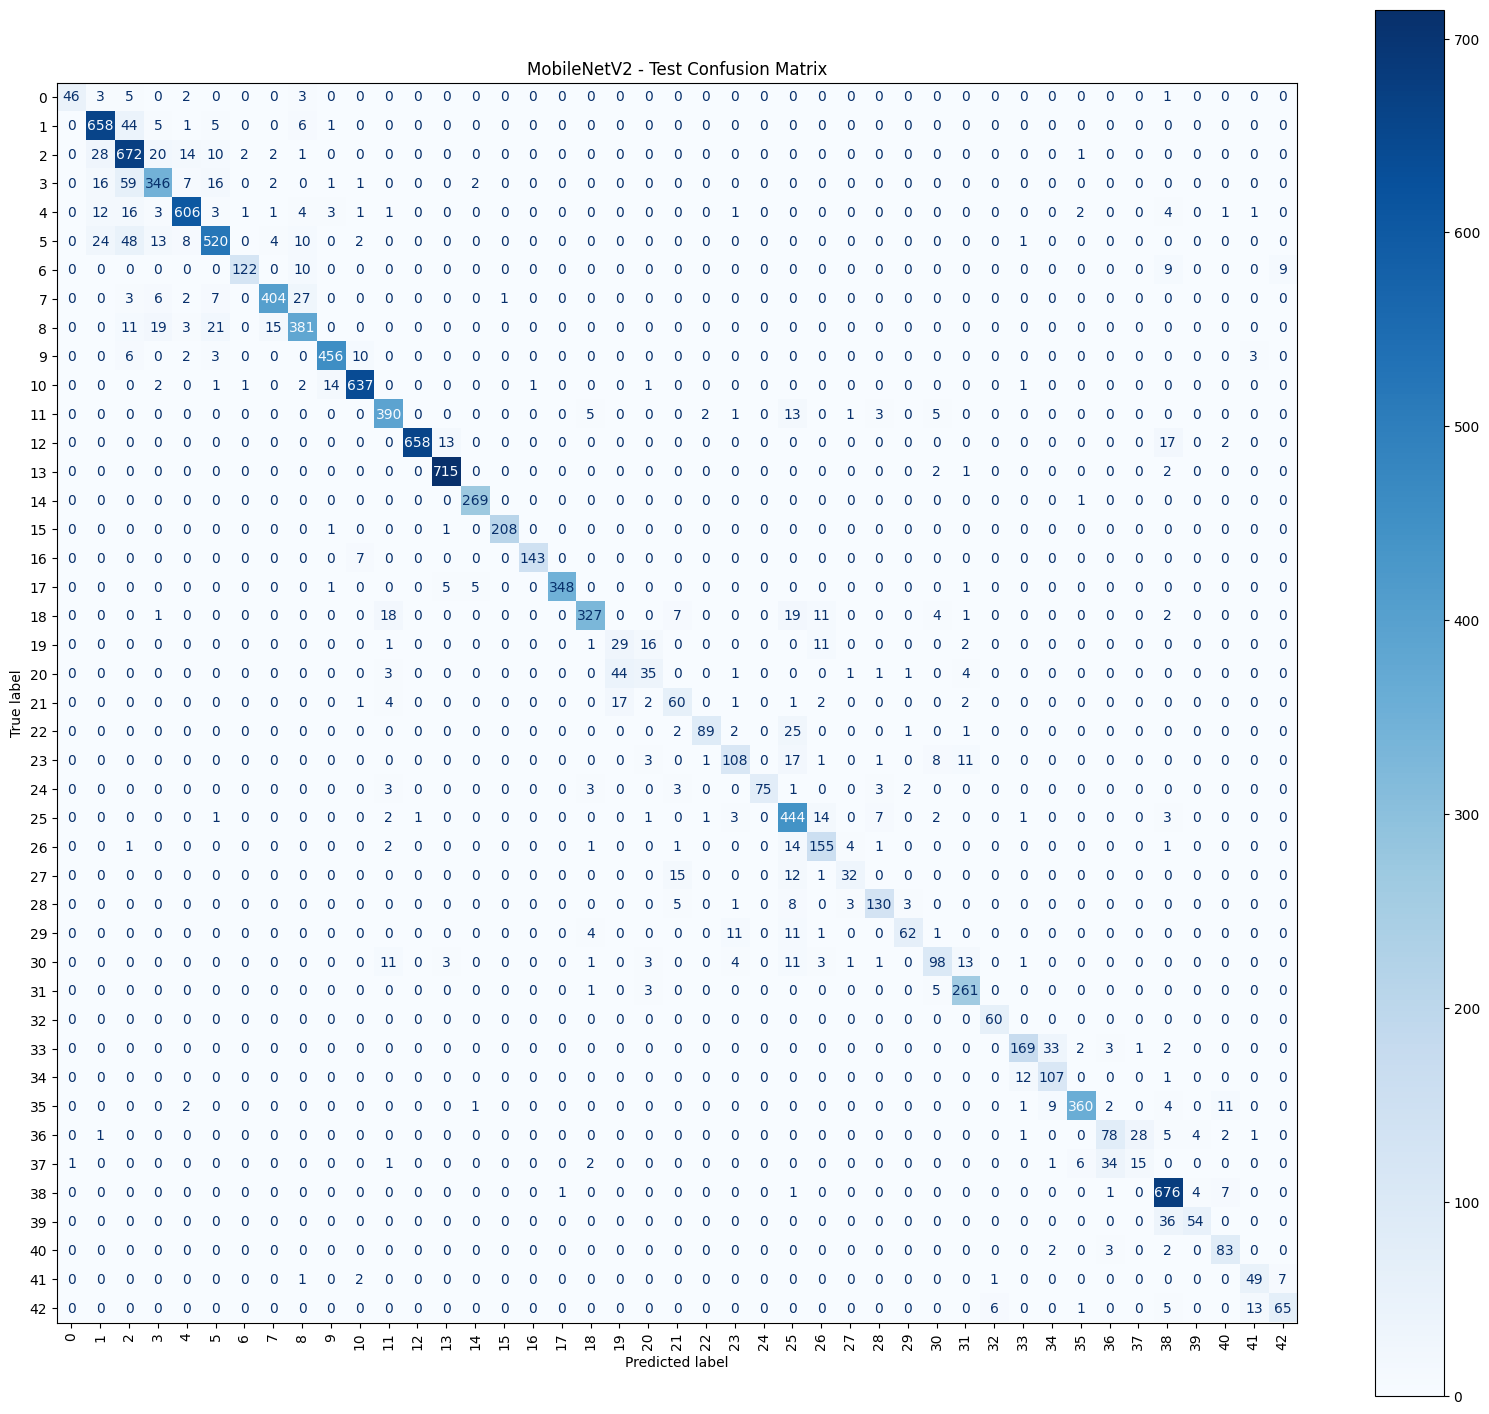

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=list(range(43)))

plt.figure(figsize=(20, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(43))
)

disp.plot(
    cmap='Blues',
    xticks_rotation='vertical',
    values_format='d'
)

plt.title('MobileNetV2 - Test Confusion Matrix')
plt.gcf().set_size_inches(20, 18)
plt.show()

In [ ]:
#without fine tuning

